# EDA on the training months (modelling plan, Phase 1)

This notebook looks at the data a model is allowed to see, and nothing else. It reads months **0–4** (the training
set) through `amldata.public()` and `amldata.labels(profile=True)`. Month 5 is the calibration set and is not
examined, so nothing here can tune the calibration step; test months 6–7 cannot be read at all.

It is different from `src/sim/eda`, which checks the simulator and reads the whole 18-month window and the truth
table. Every number here is something a model could legitimately see, plus the training labels.

**Seven questions**, one section each. Each section writes to the report (`<report>/report.md`) and saves its
figure; two sections also write a CSV.

| § | Question | Output |
|---|---|---|
| 1 | What is in the application table? | input to Phase 2 cleaning |
| 2 | Which application columns separate launderers, and does it hold for real-customer mules? | `univariate_tests.csv` |
| 3 | What does a week of activity look like, by week since opening? Label maturity. Closure footprint | |
| 4 | When does laundering start on the weekly clock? | |
| 5 | Which candidate features carry signal, and when? | `feature_screen.csv` |
| 6 | Which simulator settings does each feature rest on? Homophily test | |
| 7 | Benford realism check (not a feature) | |
| 8 | Proposed feature list for Phase 3 | |

**How to run.** From the repo root, `PYTHONPATH=src python -m features eda` executes this notebook on
`data/v1_full` and saves the executed copy here; `--out data/v1 --report outputs/modelling/eda/v1_50k` runs it on the
50k data. Interactively, set `EDA_DATA` and `EDA_REPORT` in the environment before starting the kernel (defaults:
`data/v1_full`, `outputs/modelling/eda`).


## 0. Setup

Paths, the months examined, helper functions (`log` writes to the report as well as the screen, `auc_ci` is the
rank AUC with a 95% interval: 0.5 means no signal, missing values rank lowest) and a DuckDB connection that holds
only the two public tables.

In [1]:
from __future__ import annotations

import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

# Find the repo root (the folder that holds src/amldata), move there and put src/ on the path, so the notebook runs
# the same from VS Code / Jupyter ("Run All" starts in notebooks/) and from `python -m features ...` (starts at the root).
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import amldata
from amldata import labels

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)
REPORT = Path(os.environ.get("EDA_REPORT", "outputs/modelling/eda"
                             + ("" if os.path.basename(OUT.rstrip("/")) == "v1_full" else f"/{os.path.basename(OUT.rstrip('/'))}")))
TRAIN = (0, 1, 2, 3, 4)                   # months used here; 5 = calibration (not examined), 6-7 = test (closed)
MAX_WEEK = 26                             # the main horizon of the modelling plan
SCREEN_WEEKS = (4, 8, 12, 26)
MIN_POS = 20                              # AUCs with fewer positives (launderers) are shown as NaN
MIN_SEP = 0.05                            # smallest |AUC - 0.5| that counts as a useful separation
CANDIDATES = ["n_rows", "money_in", "money_out", "max_in", "n_payers", "n_payees", "new_payer_share",
              "passthrough_wk", "out_1h_share", "out_24h_share", "med_delay_min", "cash_share", "internal_share",
              "abroad_share", "hr_share", "night_share", "money_in_cum", "n_rows_cum",
              "self_vs_past_in", "self_vs_past_payers", "peer_ratio_in", "income_fit_in"]   # weekly features, section 3
HIGH_RISK = ("Mexico", "Turkey", "Morocco", "UAE")
SENTINEL_COLS = ["prev_address_months_count", "bank_months_count", "current_address_months_count",
                 "session_length_in_minutes", "device_distinct_emails_8w", "intended_balcon_amount", "velocity_6h"]
SKEWED_COLS = ["name_email_similarity", "days_since_request", "velocity_6h", "velocity_24h", "velocity_4w",
               "zip_count_4w", "bank_branch_count_8w", "intended_balcon_amount"]

REPORT.mkdir(parents=True, exist_ok=True)
_lines: list[str] = []
T0 = time.time()


def log(msg: str = "") -> None:
    print(msg)
    _lines.append(str(msg))


def header(title: str) -> None:
    log("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)


def table(df: pd.DataFrame, floatfmt: str = ".4f", index: bool = True) -> None:
    log(df.to_markdown(index=index, floatfmt=floatfmt))
    log("")


def savefig(fig, name: str) -> None:
    """Save the figure for the report and, inside a notebook kernel, show it inline too."""
    fig.tight_layout()
    fig.savefig(REPORT / f"{name}.png", dpi=120)
    if "ipykernel" in sys.modules:
        from IPython.display import display
        display(fig)
    plt.close(fig)
    print(f"  [fig] {REPORT / name}.png")


def auc_ci(x, y, n_boot: int = 1000, seed: int = 0) -> tuple[float, float, float]:
    """Rank AUC (Mann-Whitney) with a 95% bootstrap interval; NaN ranks lowest. 0.5 = no signal.

    Each launderer gets a placement value: the share of normal accounts it scores above (ties count half). The AUC is
    the mean of these values, and resampling them gives the interval. Normal accounts are not resampled: with ~164,000
    of them their own noise is negligible next to that of a few hundred launderers. Fewer than MIN_POS launderers: all
    NaN. If every launderer has the same score, resampling cannot measure the uncertainty and the interval is NaN.
    """
    x, y = np.asarray(x, dtype=float), np.asarray(y).astype(bool)
    if y.sum() < MIN_POS or (~y).sum() == 0:
        return np.nan, np.nan, np.nan
    x = np.where(np.isnan(x), -np.inf, x)
    neg, pos = np.sort(x[~y]), x[y]
    place = (np.searchsorted(neg, pos, "left") + np.searchsorted(neg, pos, "right")) / (2 * len(neg))
    place = np.sort(place)                    # so the interval does not depend on the order rows arrive in
    if np.all(place == place[0]):
        return place.mean(), np.nan, np.nan
    boots = np.random.default_rng(seed).choice(place, size=(n_boot, len(place))).mean(axis=1)
    return place.mean(), *np.percentile(boots, [2.5, 97.5])


def auc_vs(x, pos, neg) -> tuple[float, float, float]:
    """auc_ci of the rows in `pos` against the rows in `neg` (boolean masks); other rows are left out."""
    keep = pos | neg
    return auc_ci(np.asarray(x, dtype=float)[keep], pos[keep])

con = amldata.public(OUT)                               # views: accounts, transactions. Nothing else.
con.execute(f"PRAGMA memory_limit='{os.environ.get('EDA_DUCKDB_MEMORY', '6GB')}'")
tmp = Path(OUT) / "features" / "duckdb_tmp"
tmp.mkdir(parents=True, exist_ok=True)
con.execute(f"PRAGMA temp_directory='{tmp.as_posix()}'")
months_sql = ", ".join(map(str, TRAIN))

log(f"DATA   : {OUT}\nREPORT : {REPORT}\nmonths : {TRAIN} (training); month 5 kept for calibration, 6-7 closed")
log(f"pandas {pd.__version__} | python {sys.version.split()[0]}")

DATA   : data/v1_full
REPORT : outputs/modelling/eda
months : (0, 1, 2, 3, 4) (training); month 5 kept for calibration, 6-7 closed
pandas 3.0.6 | python 3.12.15


## 1. The application table

What the 29 BAF columns look like before any cleaning: BAF's missing codes (−1, or a negative amount), the
levels of the five categorical columns, skew, and pairs of columns that move together. This table is the input
to the Phase 2 cleaning recipe. Note that negative `credit_risk_score` values are real scores, not missing codes.


1. APPLICATION TABLE (input to Phase 2 cleaning)
accounts in months (0, 1, 2, 3, 4): 164,819; launderers 455 (0.276%); by type: {'fake': 320, 'unwitting': 69, 'witting': 66}
24 numeric and 5 categorical application columns; true NaN: 0

BAF codes: share of rows with a negative value (BAF writes missing as -1 or a negative amount):
|                              |   share_negative |       min | note                                                  |
|:-----------------------------|-----------------:|----------:|:------------------------------------------------------|
| intended_balcon_amount       |           0.7299 |  -12.1995 | missing code -> NaN + flag                            |
| prev_address_months_count    |           0.6944 |   -1.0000 | missing code -> NaN + flag                            |
| bank_months_count            |           0.2550 |   -1.0000 | missing code -> NaN + flag                            |
| credit_risk_score            |           0.0181 | -165.0000 | re

|                                  |   skew |    distinct |
|:---------------------------------|-------:|------------:|
| days_since_request               | 8.8619 | 164523.0000 |
| prev_address_months_count        | 3.9720 |    355.0000 |
| session_length_in_minutes        | 3.2291 | 164429.0000 |
| bank_branch_count_8w             | 2.6812 |   2202.0000 |
| intended_balcon_amount           | 2.4315 | 164681.0000 |
| device_distinct_emails_8w        | 2.3270 |      4.0000 |
| current_address_months_count     | 1.4118 |    412.0000 |
| zip_count_4w                     | 1.3442 |   5930.0000 |
| proposed_credit_limit            | 1.1978 |     12.0000 |
| date_of_birth_distinct_emails_4w | 0.5516 |     39.0000 |
| customer_age                     | 0.5015 |      9.0000 |
| bank_months_count                | 0.4823 |     33.0000 |



application columns with |Spearman| > 0.5 (Phase 2 proposes keeping both of each pair; regularisation handles them):
| a                         | b                            |   spearman |
|:--------------------------|:-----------------------------|-----------:|
| prev_address_months_count | current_address_months_count |    -0.6600 |
| credit_risk_score         | proposed_credit_limit        |     0.6427 |
| bank_branch_count_8w      | bank_months_count            |     0.5105 |



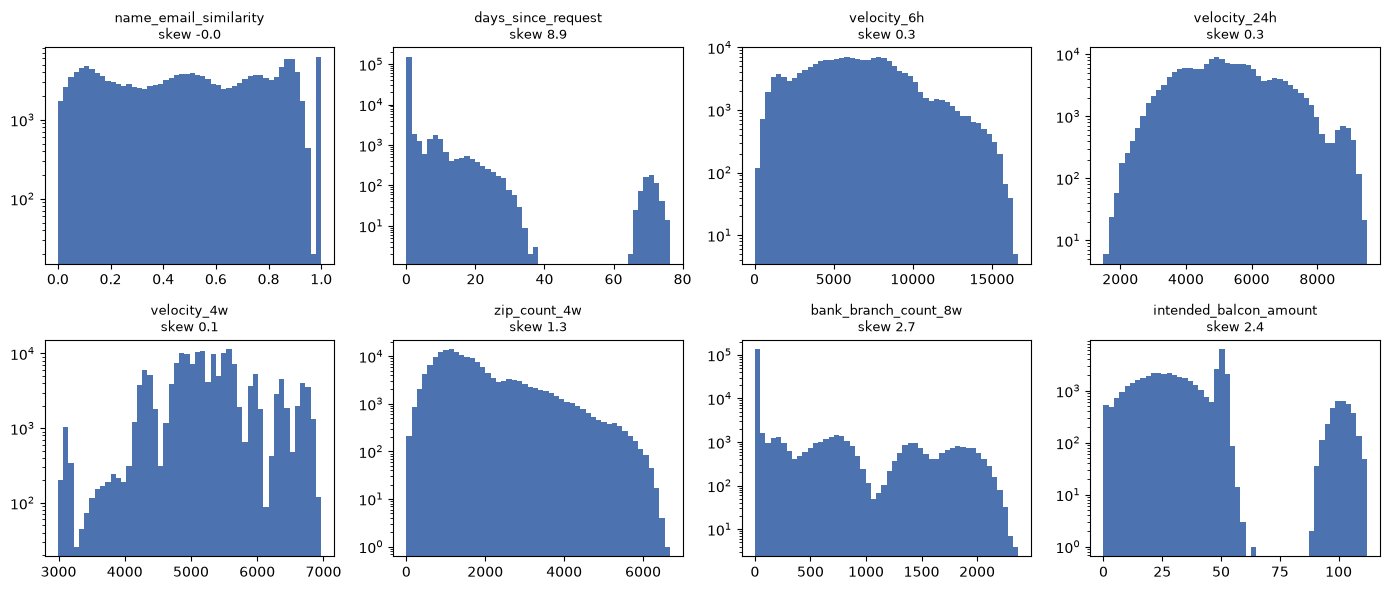

  [fig] outputs/modelling/eda/01_application_skew.png


In [2]:
header("1. APPLICATION TABLE (input to Phase 2 cleaning)")

acc = con.execute(f"SELECT * FROM accounts WHERE open_month IN ({months_sql})").df()
lab = labels(OUT, months=TRAIN, profile=True)
acc = acc.merge(lab, on=["account_id", "open_month"], how="left", validate="1:1")
acc["group"] = np.where(acc["is_launderer"] == 0, "normal",
                        np.where(acc["profile"] == "fake", "fake", "real mule"))
y = acc["is_launderer"].to_numpy()
feat_cols = [c for c in acc.columns if c not in ("account_id", "open_month", "open_day", "is_launderer", "profile", "group")]
num_cols = acc[feat_cols].select_dtypes("number").columns.tolist()
cat_cols = [c for c in feat_cols if c not in num_cols]

log(f"accounts in months {TRAIN}: {len(acc):,}; launderers {int(y.sum()):,} ({y.mean():.3%}); "
    f"by type: {acc.loc[acc.is_launderer == 1, 'profile'].value_counts().to_dict()}")
log(f"{len(num_cols)} numeric and {len(cat_cols)} categorical application columns; true NaN: "
    f"{int(acc[feat_cols].isna().sum().sum())}")

log("\nBAF codes: share of rows with a negative value (BAF writes missing as -1 or a negative amount):")
sent = pd.DataFrame({"share_negative": {c: float((acc[c] < 0).mean()) for c in SENTINEL_COLS + ["credit_risk_score"]}})
sent["min"] = [acc[c].min() for c in sent.index]
sent["note"] = ["missing code -> NaN + flag"] * len(SENTINEL_COLS) + ["real values: the score runs negative; keep as is"]
sent.loc["velocity_6h", "note"] = f"{int((acc['velocity_6h'] < 0).sum())} negative rows here; Phase 2 clips at 0 (fixed rule)"
table(sent.sort_values("share_negative", ascending=False))

log("categorical levels:")
table(pd.DataFrame({"levels": acc[cat_cols].nunique(),
                    "values": [", ".join(sorted(acc[c].astype(str).unique())) for c in cat_cols]}), index=True)

log("skew of numeric columns with more than 2 values (Phase 2 logs a column for the linear models only where log1p")
log("brings its skew closer to 0):")
multi = [col for col in num_cols if acc[col].nunique() > 2]     # skew means nothing for 0/1 columns
sk = acc[multi].skew().sort_values(key=np.abs, ascending=False).to_frame("skew")
sk["distinct"] = acc[multi].nunique()
table(sk.head(12))

corr = acc[num_cols].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), 1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs[pairs["spearman"].abs() > 0.5].sort_values("spearman", key=np.abs, ascending=False)
log("application columns with |Spearman| > 0.5 (Phase 2 proposes keeping both of each pair; regularisation handles them):")
table(pairs, index=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), SKEWED_COLS):
    v = acc[c].to_numpy(dtype=float)
    ax.hist(v[v >= 0], bins=50, color="#4c72b0")
    ax.set_title(f"{c}\nskew {acc[c].skew():.1f}", fontsize=9)
    ax.set_yscale("log")
savefig(fig, "01_application_skew")

## 2. Application columns vs the label, by hidden type

For every application column: rank AUC and a significance test against `is_launderer` on months 0–4, then the
same AUC for fake accounts alone and for real-customer mules (witting + unwitting) alone. If only fake accounts
separate, the application can buy a head start on fakes only (the "ceiling on earliness" trap in the plan).
BAF's missing codes (−1 or a negative amount) are also scored as 0/1 flags (`<col>_missing`), since Phase 2 turns
them into flags. Each AUC has a 95% interval from resampling the launderers. The two types can separate on different columns, even in
opposite directions, which cancels in the all-launderer AUC; so the table is sorted by the largest of the three
separations and shows every column.
A small p-value with a few hundred positives is support for a feature, not proof that it is useful.


2. APPLICATION COLUMNS VS is_launderer (months 0-4), BY HIDDEN TYPE


univariate AUC vs the label (0.5 = none) with a 95% interval, for all launderers, fake accounts and real-customer
mules, with Mann-Whitney (numeric) or chi-square + Cramer's V (categorical). Categorical AUC uses the level's
launderer rate as the score. Sorted by the largest of the three separations. A small p is support, not proof.
| feature                              | kind         | auc_all             | auc_fake_vs_normal   | auc_real_vs_normal   |   mann_whitney_p |   chi2_p |   cramers_v |
|:-------------------------------------|:-------------|:--------------------|:---------------------|:---------------------|-----------------:|---------:|------------:|
| customer_age                         | numeric      | 0.529 (0.498-0.557) | 0.649 (0.617-0.678)  | 0.246 (0.206-0.284)  |           0.0263 | nan      |    nan      |
| device_os                            | categorical  | 0.639 (0.614-0.662) | 0.688 (0.660-0.714)  | 0.520 (0.477-0.560)  |         nan      |   0.0000 |      0.0

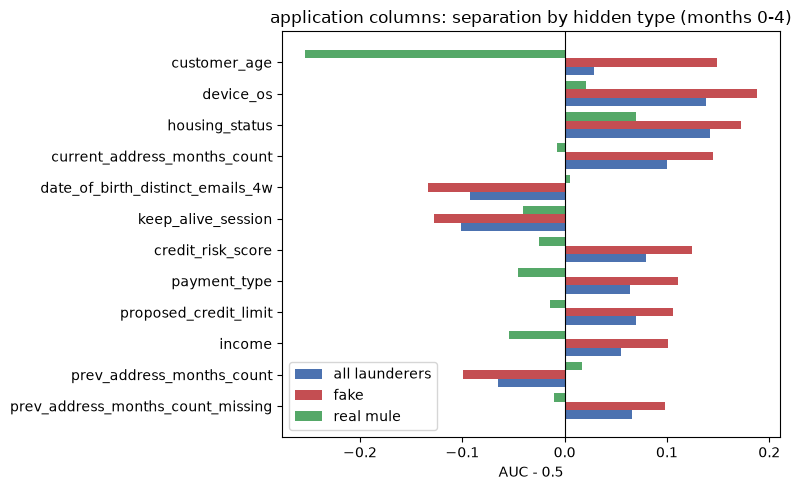

  [fig] outputs/modelling/eda/02_application_auc_by_type.png


In [3]:
header("2. APPLICATION COLUMNS VS is_launderer (months 0-4), BY HIDDEN TYPE")

rows = []
y_fake = (acc["group"] == "fake").to_numpy()
y_real = (acc["group"] == "real mule").to_numpy()
normal = (acc["group"] == "normal").to_numpy()
GROUPS = {"auc_all": y == 1, "auc_fake_vs_normal": y_fake, "auc_real_vs_normal": y_real}



def auc_by_type(score) -> dict:
    """AUC and 95% interval of one score: all launderers, fake accounts and real-customer mules, each vs normal."""
    out = {}
    for name, pos in GROUPS.items():
        out[name], out[f"{name}_lo"], out[f"{name}_hi"] = auc_vs(score, pos, normal)
    return out

flags = {f"{col}_missing": (acc[col] < 0).astype(float) for col in SENTINEL_COLS if col != "velocity_6h"}
numeric = {col: acc[col] for col in num_cols} | flags
for c, values in numeric.items():
    x = values.to_numpy(dtype=float)
    pos, neg = x[y == 1], x[y == 0]
    mw = stats.mannwhitneyu(pos, neg, alternative="two-sided").pvalue
    tt = stats.ttest_ind(pos, neg, equal_var=False).pvalue
    rows.append({"feature": c, "kind": "missing flag" if c in flags else "numeric", **auc_by_type(x),
                 "mann_whitney_p": mw, "welch_t_p": tt, "chi2_p": np.nan, "cramers_v": np.nan,
                 "mean_launderer": pos.mean(), "mean_normal": neg.mean()})


def info_gain(ct: pd.DataFrame) -> float:
    """Information gain of the label from a categorical column (entropy in bits)."""
    p = ct.to_numpy(dtype=float)
    py = p.sum(0) / p.sum()
    h = lambda q: -np.nansum(q * np.log2(np.where(q > 0, q, 1)))
    cond = sum((row.sum() / p.sum()) * h(row / row.sum()) for row in p if row.sum() > 0)
    return h(py) - cond


for c in cat_cols:
    ct = pd.crosstab(acc[c], acc["is_launderer"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
    rate = acc.groupby(c)["is_launderer"].mean()
    rows.append({"feature": c, "kind": "categorical", **auc_by_type(acc[c].map(rate).to_numpy(dtype=float)),
                 "mann_whitney_p": np.nan, "welch_t_p": np.nan, "chi2_p": p, "cramers_v": v,
                 "info_gain_bits": info_gain(ct), "mean_launderer": np.nan, "mean_normal": np.nan})

uni = pd.DataFrame(rows)
uni["separation"] = (uni[list(GROUPS)] - 0.5).abs().max(axis=1)   # largest of the three, so one type's signal shows
uni = uni.sort_values("separation", ascending=False)
uni.to_csv(REPORT / "univariate_tests.csv", index=False)
log("univariate AUC vs the label (0.5 = none) with a 95% interval, for all launderers, fake accounts and real-customer")
log("mules, with Mann-Whitney (numeric) or chi-square + Cramer's V (categorical). Categorical AUC uses the level's")
log("launderer rate as the score. Sorted by the largest of the three separations. A small p is support, not proof.")
with_ci = lambda g: uni.apply(lambda r: f"{r[g]:.3f} ({r[g + '_lo']:.3f}-{r[g + '_hi']:.3f})", axis=1)
table(uni[["feature", "kind"]].assign(**{g: with_ci(g) for g in GROUPS}, mann_whitney_p=uni["mann_whitney_p"],
                                      chi2_p=uni["chi2_p"], cramers_v=uni["cramers_v"]), index=False)
baf = uni[uni["kind"] != "missing flag"]
sig = baf[(baf["mann_whitney_p"] < 0.01) | (baf["chi2_p"] < 0.01)]
separates = lambda g: uni.loc[(uni[g + "_lo"] > 0.5) | (uni[g + "_hi"] < 0.5), "feature"].tolist()
log(f"{len(sig)} of {len(baf)} BAF columns significant at p < 0.01 against all launderers ({len(flags)} missing flags not counted).")
log(f"columns whose 95% interval excludes 0.5, by separation: fake accounts {len(separates('auc_fake_vs_normal'))}: "
    f"{separates('auc_fake_vs_normal')}")
log(f"real-customer mules {len(separates('auc_real_vs_normal'))}: {separates('auc_real_vs_normal')}")
age = uni.set_index("feature").loc["customer_age"]
log(f"  -> the two types separate on different columns, sometimes in opposite directions: customer_age has AUC "
    f"{age['auc_fake_vs_normal']:.2f} for fakes and {age['auc_real_vs_normal']:.2f} for real mules, {age['auc_all']:.2f} for all.")
log("     Real mules' age signal comes from the simulator setting profiles.real_mule_age_weights (Cifas mule ages): an")
log("     assumption the report must name. Age is allowed as a model input (decision 19 Oct 2026); Variant II tests fairness.")

top = uni.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
yy = np.arange(len(top))
for k, (col, lab_, colr) in enumerate([("auc_all", "all launderers", "#4c72b0"), ("auc_fake_vs_normal", "fake", "#c44e52"),
                                       ("auc_real_vs_normal", "real mule", "#55a868")]):
    ax.barh(yy + (k - 1) * 0.27, top[col] - 0.5, height=0.27, label=lab_, color=colr)
ax.set_yticks(yy, top["feature"])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("AUC - 0.5")
ax.set_title("application columns: separation by hidden type (months 0-4)")
ax.legend()
savefig(fig, "02_application_auc_by_type")

## 3. A week of activity, by week since opening

An account-week panel for weeks 0–26 (the main horizon), built in DuckDB with only rows up to each week's
cut-off (`day <= open_day + 7w + 6`, the clock used by `labels(weeks_since_open=w)`). It holds every candidate
feature of Phase 3: volume, speed (an ASOF join pairs each payment out with the latest payment in), counterparties,
mix, self-vs-past (median and MAD of earlier weeks), peers and income fit.

Four things are read off it: medians and means per week for launderers vs normal accounts (open weeks only), a
direct test of the weeks **before laundering starts**, the **label maturity** curve
(`mule_by_day` counts fake accounts from week 0, `started_by_day` only once laundering has begun), and the
**closure footprint**: activity stops once the bank closes an account, and only confirmed launderers are closed. Weeks
after a closure are a label giveaway a live model never sees, so they are dropped with `labels()`'s `open_by_day`. A
week with no rows is not used as the closure test: normal accounts have a few too.


3. A WEEK OF ACTIVITY, BY WEEK SINCE OPENING (weeks 0-26) + LABEL MATURITY


account-week panel for months (0, 1, 2, 3, 4), weeks 0-26: 4,450,113 rows in 18s



label maturity on training accounts (4s): launderers labelled under each label, by week
|   week |   mule_by_day |   started_by_day |   is_launderer |
|-------:|--------------:|-----------------:|---------------:|
|      0 |           320 |                0 |            455 |
|      1 |           322 |                2 |            455 |
|      4 |           332 |               12 |            455 |
|      8 |           340 |               32 |            455 |
|     12 |           344 |              176 |            455 |
|     17 |           348 |              348 |            455 |
|     26 |           361 |              361 |            455 |
|     39 |           379 |              379 |            455 |
|     52 |           401 |              401 |            455 |
|     78 |           455 |              455 |            455 |


per open account-week, launderers (1) vs normal (0): medians (_med) and means (_avg), weeks 0, 1, 4, 8, 12, 26.
Launderers mix accounts before and after 


before laundering starts: weeks 0-7, launderers before their start week vs normal accounts, one mean per account (fake 320, real mules 135, normal 164,364)
| feature             | fake                | real mule           |
|:--------------------|:--------------------|:--------------------|
| n_rows              | 0.477 (0.445-0.506) | 0.514 (0.465-0.561) |
| money_in            | 0.583 (0.551-0.612) | 0.462 (0.414-0.507) |
| money_out           | 0.568 (0.536-0.596) | 0.463 (0.413-0.508) |
| max_in              | 0.583 (0.551-0.612) | 0.459 (0.411-0.505) |
| n_payers            | 0.493 (0.462-0.521) | 0.481 (0.430-0.528) |
| n_payees            | 0.481 (0.449-0.508) | 0.529 (0.481-0.577) |
| new_payer_share     | 0.483 (0.451-0.512) | 0.487 (0.439-0.534) |
| passthrough_wk      | 0.462 (0.430-0.491) | 0.457 (0.406-0.504) |
| out_1h_share        | 0.489 (0.470-0.508) | 0.473 (0.441-0.503) |
| out_24h_share       | 0.534 (0.499-0.564) | 0.478 (0.428-0.526) |
| med_delay_min       | 0.5


activity that stops (weeks 0-77): accounts whose last active week is before week 77, and zero-activity weeks
|   is_launderer |   accounts |   stopped_before_week_77 |   zero_activity_weeks |   account_weeks |
|---------------:|-----------:|-------------------------:|----------------------:|----------------:|
|              0 |     164364 |                        1 |                    82 |        12820392 |
|              1 |        455 |                      116 |                  6003 |           35490 |

  -> 116 of 455 launderers stop early, against 1 normal account(s). Only the bank's rules close accounts, only after a
     confirmed (true) alert, so weeks after a closure are a label giveaway a live model never sees (the harness
     counts closed accounts as caught). A zero-row week is not a clean closure test: normal accounts have 82 too.
     labels() returns open_by_day (decision 10 Oct 2026: 0 once the bank has closed the account; a bank knows its
     closures). The screen

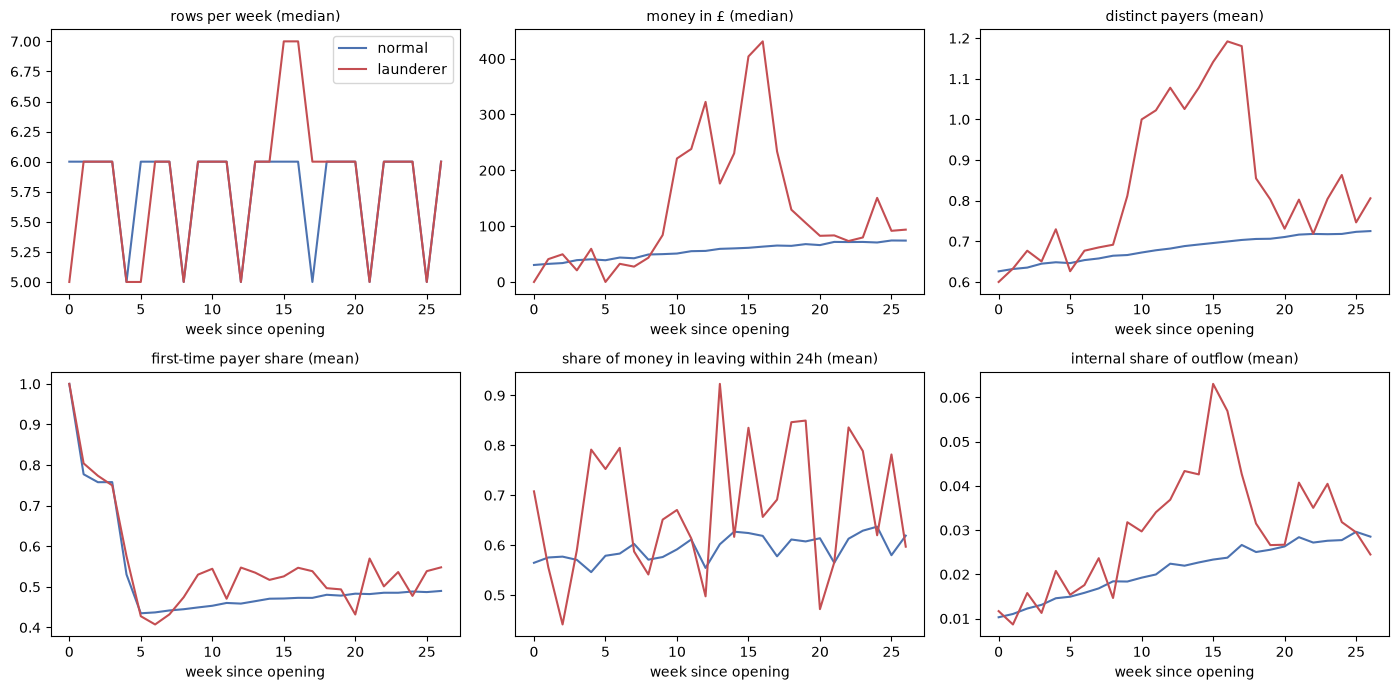

  [fig] outputs/modelling/eda/03_weekly_activity_by_group.png


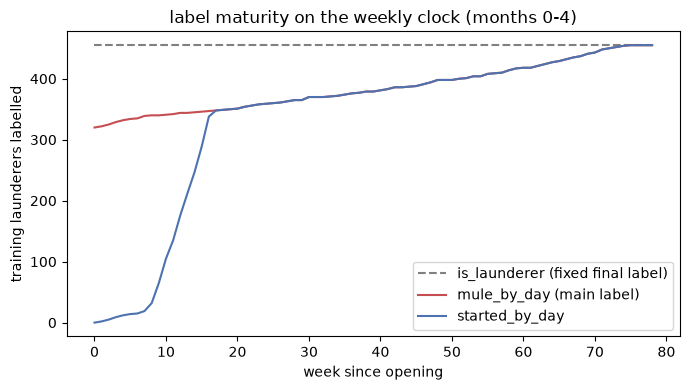

  [fig] outputs/modelling/eda/04_label_maturity.png


In [4]:
header("3. A WEEK OF ACTIVITY, BY WEEK SINCE OPENING (weeks 0-26) + LABEL MATURITY")

t = time.time()
PANEL = f"""
WITH acc AS (
    SELECT account_id, open_day, income, customer_age FROM accounts WHERE open_month IN ({months_sql})),
t AS (
    SELECT x.account_id, x.direction, x.counterparty_id, x.amount, x.payment_type, x.receiver_bank_location,
           (x.day - a.open_day) // 7 AS w,
           x.day * 86400 + CAST(substr(x.time, 1, 2) AS INT) * 3600 + CAST(substr(x.time, 4, 2) AS INT) * 60
               + CAST(substr(x.time, 7, 2) AS INT) AS ts,
           CAST(substr(x.time, 1, 2) AS INT) < 6 AS night,
           row_number() OVER (PARTITION BY x.account_id, x.counterparty_id ORDER BY x.day, x.time) AS nth_with_cp
    FROM transactions x JOIN acc a USING (account_id)
    WHERE x.day <= a.open_day + 7 * {MAX_WEEK} + 6),
ins AS (SELECT account_id, ts FROM t WHERE direction = 'in'),
outs AS (
    SELECT o.account_id, o.w, o.amount, o.ts - i.ts AS delay
    FROM (SELECT account_id, w, amount, ts FROM t WHERE direction = 'out') o
    ASOF LEFT JOIN ins i ON o.account_id = i.account_id AND o.ts >= i.ts),
speed AS (
    SELECT account_id, w,
           coalesce(sum(amount) FILTER (WHERE delay <= 3600), 0)  AS out_1h,
           coalesce(sum(amount) FILTER (WHERE delay <= 86400), 0) AS out_24h,
           median(delay) / 60.0 AS med_delay_min
    FROM outs GROUP BY 1, 2),
wk AS (
    SELECT account_id, w,
           count(*) AS n_rows,
           coalesce(sum(amount) FILTER (WHERE direction = 'in'), 0)  AS money_in,
           coalesce(sum(amount) FILTER (WHERE direction = 'out'), 0) AS money_out,
           coalesce(max(amount) FILTER (WHERE direction = 'in'), 0)  AS max_in,
           count(DISTINCT counterparty_id) FILTER (WHERE direction = 'in' AND counterparty_id <> 'CASH') AS n_payers,
           count(DISTINCT counterparty_id) FILTER (WHERE direction = 'out' AND counterparty_id NOT IN ('CASH', 'CARD_MERCHANTS')) AS n_payees,
           count(DISTINCT counterparty_id) FILTER (WHERE direction = 'in' AND counterparty_id <> 'CASH' AND nth_with_cp = 1) AS n_new_payers,
           avg(CASE WHEN payment_type LIKE 'Cash%' THEN 1 ELSE 0 END) AS cash_share,
           coalesce(sum(amount) FILTER (WHERE direction = 'out' AND counterparty_id LIKE 'A%'), 0) AS internal_out,
           coalesce(sum(amount) FILTER (WHERE direction = 'out' AND receiver_bank_location <> 'UK'), 0) AS abroad_out,
           coalesce(sum(amount) FILTER (WHERE direction = 'out' AND receiver_bank_location IN ('{"', '".join(HIGH_RISK)}')), 0) AS hr_out,
           avg(CASE WHEN night THEN 1 ELSE 0 END) AS night_share
    FROM t GROUP BY 1, 2),
grid AS (SELECT account_id, open_day, income, customer_age, unnest(range(0, {MAX_WEEK + 1})) AS w FROM acc),
g AS (
    SELECT grid.account_id, grid.w, grid.income, grid.customer_age,
           coalesce(n_rows, 0) n_rows, coalesce(money_in, 0) money_in, coalesce(money_out, 0) money_out,
           coalesce(max_in, 0) max_in, coalesce(n_payers, 0) n_payers, coalesce(n_payees, 0) n_payees,
           coalesce(n_new_payers, 0) n_new_payers, cash_share, coalesce(internal_out, 0) internal_out,
           coalesce(abroad_out, 0) abroad_out, coalesce(hr_out, 0) hr_out, night_share,
           coalesce(out_1h, 0) out_1h, coalesce(out_24h, 0) out_24h, med_delay_min
    FROM grid LEFT JOIN wk USING (account_id, w) LEFT JOIN speed USING (account_id, w))
SELECT *,
    n_new_payers / nullif(n_payers, 0)                                   AS new_payer_share,
    least(money_out, money_in) / nullif(money_in, 0)                     AS passthrough_wk,
    out_1h / nullif(money_in, 0)                                         AS out_1h_share,
    out_24h / nullif(money_in, 0)                                        AS out_24h_share,
    internal_out / nullif(money_out, 0)                                  AS internal_share,
    abroad_out / nullif(money_out, 0)                                    AS abroad_share,
    hr_out / nullif(money_out, 0)                                        AS hr_share,
    sum(money_in) OVER (PARTITION BY account_id ORDER BY w)              AS money_in_cum,
    sum(n_rows)   OVER (PARTITION BY account_id ORDER BY w)              AS n_rows_cum,
    (money_in - median(money_in) OVER past) / nullif(mad(money_in) OVER past, 0) AS self_vs_past_in,
    (n_payers - median(n_payers) OVER past) / nullif(mad(n_payers) OVER past, 0) AS self_vs_past_payers,
    count(*) OVER past                                                   AS n_past_weeks,
    money_in / nullif(median(money_in) OVER (PARTITION BY income, customer_age, w), 0) AS peer_ratio_in,
    money_in / nullif(median(money_in) OVER (PARTITION BY income, w), 0)               AS income_fit_in
FROM g
WINDOW past AS (PARTITION BY account_id ORDER BY w ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
"""
con.execute(f"CREATE OR REPLACE TABLE panel AS {PANEL}")
# self-vs-past needs at least 4 earlier weeks, as in the plan
con.execute("UPDATE panel SET self_vs_past_in = NULL, self_vs_past_payers = NULL WHERE n_past_weeks < 4")
n_panel = con.execute("SELECT count(*) FROM panel").fetchone()[0]
log(f"account-week panel for months {TRAIN}, weeks 0-{MAX_WEEK}: {n_panel:,} rows in {time.time() - t:.0f}s")

con.register("lab", lab[["account_id", "is_launderer", "profile"]])
# label maturity on the weekly clock, weeks 0-78 (one labels() call per week; the only hidden columns used)
t = time.time()
mat, lab_weeks = [], []
first_start = pd.Series(np.nan, index=lab["account_id"])
for w in range(0, 79):
    lw = labels(OUT, months=TRAIN, weeks_since_open=w)
    if w <= MAX_WEEK:
        lab_weeks.append(lw[["account_id", "started_by_day", "open_by_day"]].assign(w=w))
    mat.append({"week": w, "mule_by_day": int(lw["mule_by_day"].sum()), "started_by_day": int(lw["started_by_day"].sum()),
                "is_launderer": int(lw["is_launderer"].sum())})
    started = lw.loc[lw["started_by_day"] == 1, "account_id"]
    first_start.loc[first_start.index.isin(started) & first_start.isna()] = w
mat = pd.DataFrame(mat).set_index("week")
con.register("lab_weeks", pd.concat(lab_weeks))           # per account and week 0-26: started, still open
log(f"\nlabel maturity on training accounts ({time.time() - t:.0f}s): launderers labelled under each label, by week")
table(mat.loc[[0, 1, 4, 8, 12, 17, 26, 39, 52, 78]], floatfmt=".0f")

by_week = con.execute("""
    SELECT w, l.is_launderer,
           count(*) n, median(n_rows) rows_med, median(money_in) in_med, median(money_out) out_med,
           avg(n_payers) payers_avg, median(n_payees) payees_med, avg(cash_share) cash_avg,
           avg(internal_share) internal_avg, avg(abroad_share) abroad_avg, avg(new_payer_share) new_payer_avg,
           avg(out_24h_share) out_24h_avg
    FROM panel p JOIN lab l USING (account_id) JOIN lab_weeks lw USING (account_id, w)
    WHERE lw.open_by_day = 1 GROUP BY 1, 2 ORDER BY 1, 2""").df()
log("\nper open account-week, launderers (1) vs normal (0): medians (_med) and means (_avg), weeks 0, 1, 4, 8, 12, 26.")
log("Launderers mix accounts before and after their start, so this table describes; the test below answers.")
table(by_week[by_week["w"].isin([0, 1, 4, 8, 12, 26])].set_index(["w", "is_launderer"]), floatfmt=".2f")

# 3a. before laundering starts: weeks 0-7 (no fake account starts before week 8), launderers' weeks before their start
# vs normal weeks. One value per account (its mean over these weeks), so the 95% interval is honest.
pre = con.execute(f"""
    SELECT p.account_id, any_value(p.income) AS income, {", ".join(f"avg({col}) AS {col}" for col in CANDIDATES)}
    FROM panel p JOIN lab_weeks lw USING (account_id, w)
    WHERE p.w <= 7 AND lw.started_by_day = 0 AND lw.open_by_day = 1
    GROUP BY 1""").df().merge(lab[["account_id", "is_launderer", "profile"]], on="account_id")
nrm = (pre["is_launderer"] == 0).to_numpy()
pre_groups = {"fake": (pre["profile"] == "fake").to_numpy(),
              "real mule": pre["profile"].isin(["witting", "unwitting"]).to_numpy()}
pre_auc = pd.DataFrame([{"feature": col, "group": g, **dict(zip(["auc", "lo", "hi"], auc_vs(pre[col], m, nrm)))}
                        for col in CANDIDATES for g, m in pre_groups.items()])
pre_auc["passes"] = ((pre_auc["lo"] > 0.5) | (pre_auc["hi"] < 0.5)) & ((pre_auc["auc"] - 0.5).abs() >= MIN_SEP)
pre_auc["auc (95% interval)"] = [f"{a:.3f} ({lo:.3f}-{hi:.3f})" for a, lo, hi in pre_auc[["auc", "lo", "hi"]].to_numpy()]
log(f"\nbefore laundering starts: weeks 0-7, launderers before their start week vs normal accounts, one mean per account "
    f"(fake {int(pre_groups['fake'].sum())}, real mules {int(pre_groups['real mule'].sum())}, normal {int(nrm.sum()):,})")
table(pre_auc.pivot(index="feature", columns="group", values="auc (95% interval)").loc[CANDIDATES], index=True)
passing = {g: pre_auc.loc[pre_auc["passes"] & (pre_auc["group"] == g), "feature"].tolist() for g in pre_groups}
log(f"  -> features with |AUC - 0.5| >= {MIN_SEP} and an interval excluding 0.5 before the start: "
    f"fake {len(passing['fake'])} of {len(CANDIDATES)} {passing['fake']}, "
    f"real mules {len(passing['real mule'])} of {len(CANDIDATES)} {passing['real mule']}.")


def within_income_auc(col: str, pos) -> float:
    """AUC of `col` for pos vs normal inside each BAF income band (bands with MIN_POS+ positives), weighted by positives."""
    aucs, weights = [], []
    for band in pre["income"].unique():
        in_band = (pre["income"] == band).to_numpy()
        a = auc_vs(pre[col], pos & in_band, nrm & in_band)[0]
        if not np.isnan(a):
            aucs.append(a)
            weights.append((pos & in_band).sum())
    return np.average(aucs, weights=weights) if aucs else np.nan


inc_check = pd.DataFrame([{"group": g, "feature": col, "auc": pre_auc.set_index(["feature", "group"]).loc[(col, g), "auc"],
                           "auc within income band": within_income_auc(col, pre_groups[g])}
                          for g in pre_groups for col in passing[g]])
log("the same AUCs inside each BAF income band (normal banking scales with BAF income only, src/sim/normal.py):")
table(inc_check, floatfmt=".3f", index=False)
top = pre["income"] == pre["income"].max()
log(f"share in the top BAF income band ({pre['income'].max()}): fake {top[pre_groups['fake']].mean():.0%}, "
    f"real mules {top[pre_groups['real mule']].mean():.0%}, normal {top[nrm].mean():.0%}")
explained = (inc_check["auc within income band"] - 0.5).abs() < MIN_SEP
log(f"  -> inside an income band, {int(explained.sum())} of {len(inc_check)} gaps fall below {MIN_SEP}: before laundering starts,")
log("     activity differs through the application's income, which the application already shows. Weeks before an")
log("     account's start can only be won on application data.")
if (~explained).any():
    log(f"     Not explained by income (or too few launderers per band to check): {inc_check.loc[~explained, 'feature'].tolist()}."
        f" With {len(pre_auc)} looks, about {0.05 * len(pre_auc):.0f} pass by chance at 95%.")

# 3b. activity that stops: the footprint of the bank's closures in the public data
stop = con.execute(f"""
    WITH acc AS (SELECT account_id, open_day FROM accounts WHERE open_month IN ({months_sql})),
    grid AS (SELECT account_id, unnest(range(0, 78)) AS w FROM acc),       -- week 78 is partial (2 days), left out
    wk AS (SELECT a.account_id, (x.day - a.open_day) // 7 AS w, count(*) n
           FROM transactions x JOIN acc a USING (account_id) GROUP BY 1, 2),
    g AS (SELECT grid.account_id, grid.w, coalesce(n, 0) n FROM grid LEFT JOIN wk USING (account_id, w)),
    la AS (SELECT account_id, max(w) FILTER (WHERE n > 0) AS last_active_w FROM g GROUP BY 1)
    SELECT l.is_launderer, count(*) AS accounts,
           sum(CASE WHEN last_active_w < 77 THEN 1 ELSE 0 END) AS stopped_before_week_77,
           (SELECT sum(CASE WHEN n = 0 THEN 1 ELSE 0 END) FROM g JOIN lab l2 USING (account_id)
             WHERE l2.is_launderer = l.is_launderer) AS zero_activity_weeks,
           (SELECT count(*) FROM g JOIN lab l2 USING (account_id) WHERE l2.is_launderer = l.is_launderer) AS account_weeks
    FROM la JOIN lab l USING (account_id) GROUP BY 1 ORDER BY 1""").df().set_index("is_launderer")
log("\nactivity that stops (weeks 0-77): accounts whose last active week is before week 77, and zero-activity weeks")
table(stop, floatfmt=".0f")
log(f"  -> {stop.loc[1, 'stopped_before_week_77']:.0f} of {stop.loc[1, 'accounts']:.0f} launderers stop early, against "
    f"{stop.loc[0, 'stopped_before_week_77']:.0f} normal account(s). Only the bank's rules close accounts, only after a")
log("     confirmed (true) alert, so weeks after a closure are a label giveaway a live model never sees (the harness")
log(f"     counts closed accounts as caught). A zero-row week is not a clean closure test: normal accounts have "
    f"{stop.loc[0, 'zero_activity_weeks']:.0f} too.")
log("     labels() returns open_by_day (decision 10 Oct 2026: 0 once the bank has closed the account; a bank knows its")
log("     closures). The screen below and Phase 3/4 drop account-weeks with open_by_day = 0.")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, title) in zip(axes.ravel(), [("rows_med", "rows per week (median)"), ("in_med", "money in £ (median)"),
                                           ("payers_avg", "distinct payers (mean)"), ("new_payer_avg", "first-time payer share (mean)"),
                                           ("out_24h_avg", "share of money in leaving within 24h (mean)"),
                                           ("internal_avg", "internal share of outflow (mean)")]):
    for lab_val, colr, name in [(0, "#4c72b0", "normal"), (1, "#c44e52", "launderer")]:
        s = by_week[by_week["is_launderer"] == lab_val]
        ax.plot(s["w"], s[col], color=colr, label=name)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("week since opening")
axes[0, 0].legend()
savefig(fig, "03_weekly_activity_by_group")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mat.index, mat["is_launderer"], color="grey", ls="--", label="is_launderer (fixed final label)")
ax.plot(mat.index, mat["mule_by_day"], color="#c44e52", label="mule_by_day (main label)")
ax.plot(mat.index, mat["started_by_day"], color="#4c72b0", label="started_by_day")
ax.set_xlabel("week since opening")
ax.set_ylabel("training launderers labelled")
ax.set_title("label maturity on the weekly clock (months 0-4)")
ax.legend()
savefig(fig, "04_label_maturity")

## 4. When laundering starts on the weekly clock

The first week in which each training launderer's `started_by_day` turns 1, by hidden type. Weeks before that
can only be won on application data (fake accounts) or not at all (real-customer mules).


4. WHEN LAUNDERING STARTS ON THE WEEKLY CLOCK (training launderers)
| profile   |   count |   min |   10% |   50% |   90% |   max |
|:----------|--------:|------:|------:|------:|------:|------:|
| fake      |     320 |     8 |     9 |    13 |    16 |    17 |
| unwitting |      69 |     1 |     4 |    42 |    69 |    74 |
| witting   |      66 |     1 |    13 |    47 |    70 |    75 |

launderers whose start lies inside the main horizon (week <= 26): 361 of 455; by type: {'fake': 320, 'unwitting': 25, 'witting': 16}
  -> weeks before an account's start week can only be won on application data (fake accounts) or not at all
     (real-customer mules). Report 'days earlier' separately for the two.


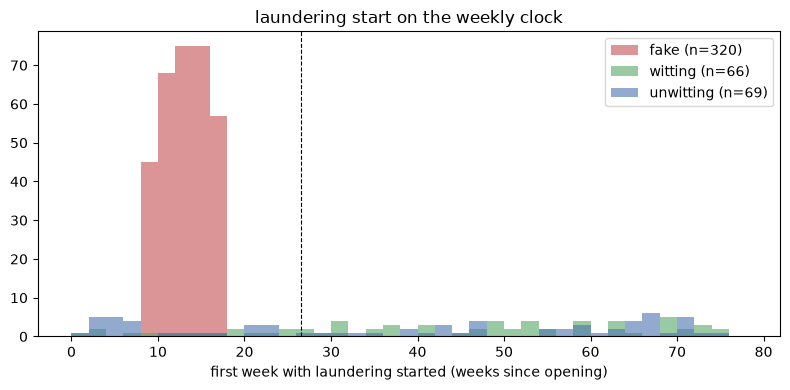

  [fig] outputs/modelling/eda/05_start_week_by_type.png


In [5]:
header("4. WHEN LAUNDERING STARTS ON THE WEEKLY CLOCK (training launderers)")

fs = first_start.dropna().rename("first_week").to_frame().join(lab.set_index("account_id")["profile"])
q = fs.groupby("profile")["first_week"].describe(percentiles=[.1, .5, .9])[["count", "min", "10%", "50%", "90%", "max"]]
table(q, floatfmt=".0f")
log(f"launderers whose start lies inside the main horizon (week <= {MAX_WEEK}): "
    f"{int((fs['first_week'] <= MAX_WEEK).sum())} of {len(fs)}; by type: "
    f"{fs[fs['first_week'] <= MAX_WEEK].groupby('profile').size().to_dict()}")
log("  -> weeks before an account's start week can only be won on application data (fake accounts) or not at all")
log("     (real-customer mules). Report 'days earlier' separately for the two.")

fig, ax = plt.subplots(figsize=(8, 4))
for prof, colr in [("fake", "#c44e52"), ("witting", "#55a868"), ("unwitting", "#4c72b0")]:
    v = fs.loc[fs["profile"] == prof, "first_week"]
    ax.hist(v, bins=np.arange(0, 80, 2), alpha=0.6, color=colr, label=f"{prof} (n={len(v)})")
ax.axvline(MAX_WEEK + 0.5, color="k", ls="--", lw=0.8)
ax.set_xlabel("first week with laundering started (weeks since opening)")
ax.set_title("laundering start on the weekly clock")
ax.legend()
savefig(fig, "05_start_week_by_type")

## 5. Candidate feature screen at weeks 4, 8, 12 and 26

Rank AUC of every candidate feature at four weeks since opening, against `mule_by_day` (the main label) and
against `started_by_day` (accounts whose laundering has begun), also split by hidden type. Only accounts the bank
has not closed are used (`open_by_day = 1`). Each AUC has a 95% interval (resampling the launderers, as in section 2);
an AUC with fewer than 20 positives is shown as NaN.
The correlation matrix at week 12 shows which candidates say the same thing.

Fixed weeks mix accounts in the middle of their ~2-week burst with accounts whose burst ended weeks ago, so they
understate weekly features (by week 26 most bursts are over). The Phase 3 notebook (`03_feature_store.ipynb`, section 3)
scores each launderer's *first laundering week* instead, which is how a weekly model meets it.


5. CANDIDATE FEATURE SCREEN AT WEEKS 4, 8, 12, 26 (months 0-4)


Accounts the bank has not closed (open_by_day = 1); AUCs with fewer than 20 positives shown as NaN.
AUC against mule_by_day (main label) by week since opening; 0.5 = no signal:
| feature             |      4 |      8 |     12 |     26 |   max_sep |
|:--------------------|-------:|-------:|-------:|-------:|----------:|
| n_rows_cum          | 0.4945 | 0.5057 | 0.6036 | 0.7088 |    0.2088 |
| money_in_cum        | 0.5787 | 0.5909 | 0.6453 | 0.6689 |    0.1689 |
| money_out           | 0.5674 | 0.5721 | 0.6422 | 0.5704 |    0.1422 |
| self_vs_past_payers | 0.5124 | 0.5047 | 0.5639 | 0.6421 |    0.1421 |
| self_vs_past_in     | 0.5159 | 0.4980 | 0.5698 | 0.6393 |    0.1393 |
| med_delay_min       | 0.5054 | 0.4787 | 0.3742 | 0.4649 |    0.1258 |
| out_1h_share        | 0.5068 | 0.5091 | 0.6210 | 0.5229 |    0.1210 |
| n_rows              | 0.5018 | 0.5031 | 0.6161 | 0.5141 |    0.1161 |
| out_24h_share       | 0.5172 | 0.5047 | 0.6104 | 0.5303 |    0.1104 |
| n_payers            | 0.5048 

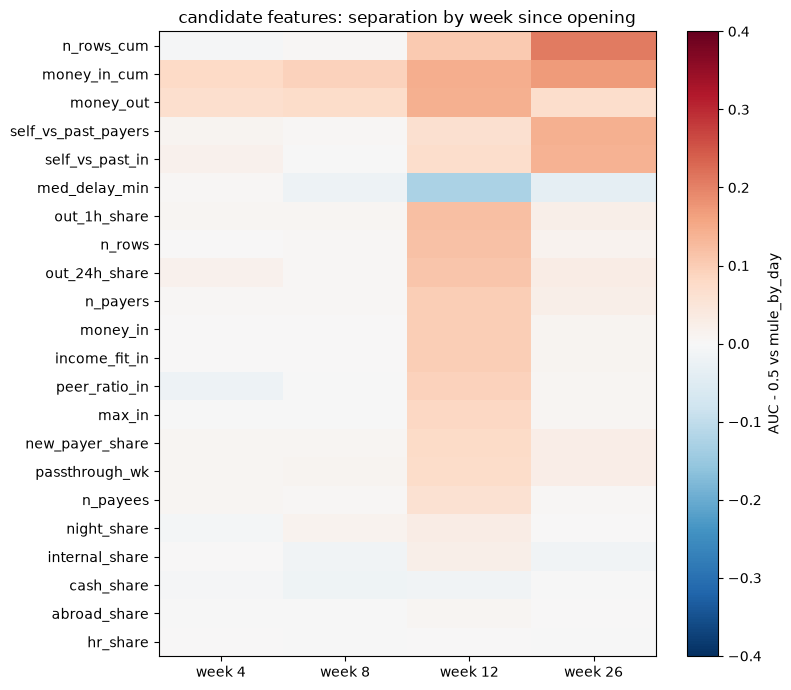

  [fig] outputs/modelling/eda/06_feature_screen_heatmap.png


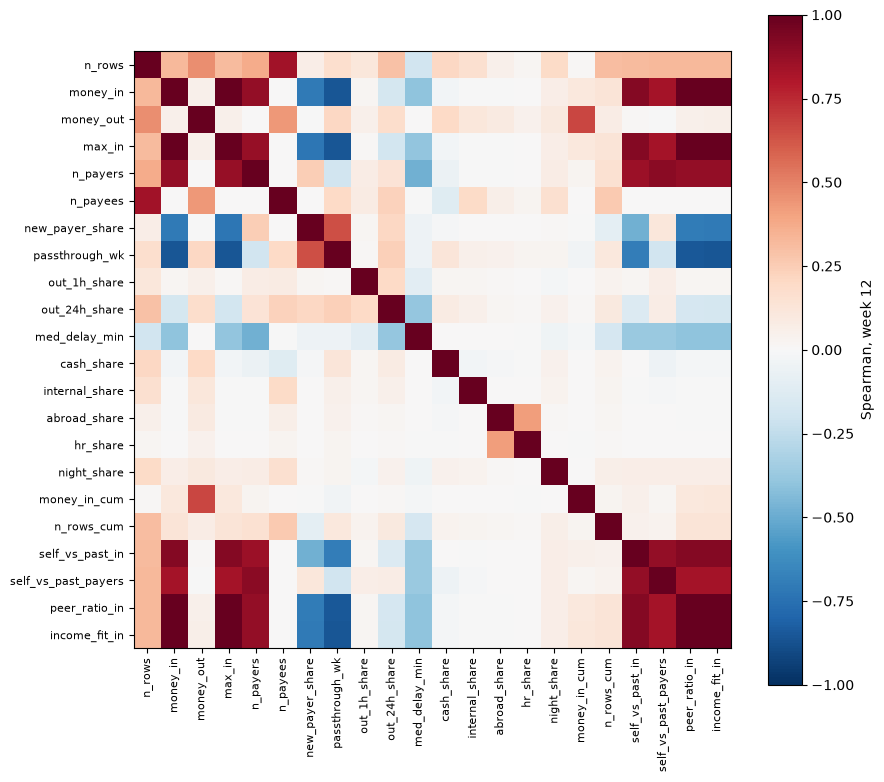

  [fig] outputs/modelling/eda/07_feature_correlation_week12.png


In [6]:
header("5. CANDIDATE FEATURE SCREEN AT WEEKS 4, 8, 12, 26 (months 0-4)")

screen = []
corr_at_12 = None
for W in SCREEN_WEEKS:
    pw = con.execute(f"SELECT * FROM panel WHERE w = {W}").df()
    lw = labels(OUT, months=TRAIN, weeks_since_open=W, profile=True)
    pw = pw.merge(lw, on="account_id", how="inner")
    pw = pw[pw["open_by_day"] == 1].reset_index(drop=True)    # accounts the bank has not closed (section 3)
    nrm = (pw["is_launderer"] == 0).to_numpy()
    mule = (pw["mule_by_day"] == 1).to_numpy()
    started = (pw["started_by_day"] == 1).to_numpy()
    fake = (pw["profile"] == "fake").to_numpy()
    tests = {"mule_by_day": (mule, ~mule), "started_by_day": (started, nrm), "fake_vs_normal": (fake, nrm),
             "real_started_vs_normal": (started & ~fake, nrm)}
    for c in CANDIDATES:
        x = pw[c].to_numpy(dtype=float)
        rec = {"week": W, "feature": c, "nonnull_share": float(np.isfinite(x).mean())}
        for name, (pos, neg) in tests.items():
            rec[f"n_{name}"] = int(pos.sum())
            rec[f"auc_{name}"], rec[f"auc_{name}_lo"], rec[f"auc_{name}_hi"] = auc_vs(x, pos, neg)
        screen.append(rec)
    if W == 12:
        corr_at_12 = pw[CANDIDATES].corr(method="spearman")
screen = pd.DataFrame(screen)
screen.to_csv(REPORT / "feature_screen.csv", index=False)

log(f"Accounts the bank has not closed (open_by_day = 1); AUCs with fewer than {MIN_POS} positives shown as NaN.")
log("AUC against mule_by_day (main label) by week since opening; 0.5 = no signal:")
piv = screen.pivot(index="feature", columns="week", values="auc_mule_by_day")
piv["max_sep"] = (piv - 0.5).abs().max(axis=1)
table(piv.sort_values("max_sep", ascending=False))
log("AUC against started_by_day (accounts whose laundering has started vs normal):")
piv2 = screen.pivot(index="feature", columns="week", values="auc_started_by_day")
log(f"launderers started by week: {screen.groupby('week')['n_started_by_day'].first().to_dict()} "
    f"(real-customer mules: {screen.groupby('week')['n_real_started_vs_normal'].first().to_dict()})")
table(piv2.loc[piv.sort_values("max_sep", ascending=False).index])
log("  -> mule_by_day counts fake accounts from week 0 even while their activity is still normal, so activity")
log("     features look weak against it in early weeks by construction. started_by_day shows what activity")
log("     can see once a burst exists; with few starts before week 8, those early AUCs are noisy.")

hi = (corr_at_12.where(np.triu(np.ones_like(corr_at_12, dtype=bool), 1)).stack().rename("spearman").reset_index())
hi = hi[hi["spearman"].abs() > 0.8].sort_values("spearman", key=np.abs, ascending=False)
log("candidate pairs with |Spearman| > 0.8 at week 12 (keep one of each for logistic regression):")
table(hi.rename(columns={"level_0": "a", "level_1": "b"}), index=False)

fig, ax = plt.subplots(figsize=(8, 7))
hm = (piv.drop(columns="max_sep") - 0.5).loc[piv.sort_values("max_sep", ascending=False).index]
im = ax.imshow(hm.to_numpy(), cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(hm.shape[1]), [f"week {w}" for w in hm.columns])
ax.set_yticks(range(hm.shape[0]), hm.index)
fig.colorbar(im, ax=ax, label="AUC - 0.5 vs mule_by_day")
ax.set_title("candidate features: separation by week since opening")
savefig(fig, "06_feature_screen_heatmap")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_at_12.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CANDIDATES)), CANDIDATES, rotation=90, fontsize=8)
ax.set_yticks(range(len(CANDIDATES)), CANDIDATES, fontsize=8)
fig.colorbar(im, ax=ax, label="Spearman, week 12")
savefig(fig, "07_feature_correlation_week12")

## 6. Simulator fingerprints and the homophily test

Each candidate feature and the `configs/sim.yaml` setting it rests on, so the report can say which results
depend on which assumptions (the 42 sensitivity runs test them). Then the homophily test (do launderers pay
each other more than chance would give?), on the payment network inside our bank: one link per pair of accounts
that paid each other at least once, direction ignored, both ends opened in months 0–4.

- **The homophily test (r < 2xy).** If a share x of the accounts in the network are launderers and y = 1 − x are
  normal, random links would join a launderer to a normal account a share 2xy of the time. The observed share of
  such mixed links, r, clearly below 2xy means homophily. A one-sided z-test gives a first answer, but it treats every
  link as independent, while links share accounts.
- **The label-shuffle test.** Move the launderer labels at random between the accounts in the network, 1,000 times;
  every account keeps its links. The share of shuffles with as few mixed links (or as many launderer–launderer links)
  as observed is the p-value. It needs no independence assumption and allows for how connected each account is.
- **Allowing for how connected each account is.** 2xy assumes every account has about the same number of links.
  The same test with x replaced by the share of link *ends* that sit on launderers removes that assumption.
- **How strong the effect is.** With launderers at 0.3%, almost every launderer link is a mixed link whether or not
  there is homophily, so r can only fall a little below 2xy and r / 2xy always looks modest. Two easier-to-read
  measures of the same fact: launderer–launderer links found vs expected by chance, and the lift (how often a
  launderer's payees are launderers, against the base rate).
- **When the links appear.** For each launderer–launderer link, its first payment against both ends' start weeks:
  links that exist before laundering starts could give a head start; links made by the laundering itself cannot.

In [7]:
header("6. SIMULATOR-FINGERPRINT AUDIT + HOMOPHILY TEST")

FINGERPRINTS = {
    "out_1h_share / out_24h_share / med_delay_min": "laundering.forward_delay_shares (RUSI speed bands); normal accounts have no in->out link at all",
    "passthrough_wk": "laundering.holder_keeps (0-10% kept) and the same R4 logic the rules use",
    "n_payers / new_payer_share": "laundering.shapes senders ('all' = every payment from a new payer); normal.transfers_in_per_month = 1.0",
    "n_payees": "laundering.shapes recipients; normal.transfers_out_per_month",
    "cash_share": "laundering.shapes in_kind cash / half_cash; normal.cash_depositor_share 0.06",
    "internal_share": "networks.internal_pieces_share 0.5 (x2 for layered shapes) vs normal.internal_share_of_transfers 0.10",
    "abroad_share / hr_share": "laundering.abroad_ratio_vs_normal 3.15 x normal.abroad_sender_share 0.07; high_risk_share_of_cross_border",
    "money_in / max_in / self_vs_past_in": "laundering.out_transfer_mean GBP 532 x shape amount_rel vs income-scaled normal amounts",
    "peer_ratio_in / income_fit_in": "normal money in scales with BAF income (ONS fifths); laundering amounts do not -> the ratio is partly a fingerprint",
    "night_share": "normal.hour_weights only; laundering uses the same hour weights, so no signal is expected",
    "application columns": "profiles.in_window_mix (73% of launderers are BAF fraud rows): the whole application signal rests on this one assumption",
}
fp = pd.DataFrame({"feature(s)": list(FINGERPRINTS), "rests on (configs/sim.yaml)": list(FINGERPRINTS.values())})
log("each candidate feature and the simulator setting it rests on; the 42 sensitivity runs test these settings:")
table(fp, index=False)

# homophily: the payment network inside our bank, one undirected link per pair, both ends opened in months 0-4
links = con.execute("""
    WITH lab_ AS (SELECT account_id, is_launderer FROM lab),
    e AS (SELECT least(x.account_id, x.counterparty_id) AS a, greatest(x.account_id, x.counterparty_id) AS b,
                 min(x.day) AS first_day
          FROM transactions x JOIN lab_ USING (account_id)
          WHERE x.direction = 'out' AND x.counterparty_id LIKE 'A%' AND x.counterparty_id <> x.account_id
          GROUP BY 1, 2)
    SELECT e.a, e.b, e.first_day, la.is_launderer AS a_l, lb.is_launderer AS b_l,
           oa.open_day AS a_open, ob.open_day AS b_open
    FROM e JOIN lab_ la ON la.account_id = e.a JOIN lab_ lb ON lb.account_id = e.b
    JOIN accounts oa ON oa.account_id = e.a JOIN accounts ob ON ob.account_id = e.b""").df()
E = len(links)
n_ll = int(((links["a_l"] == 1) & (links["b_l"] == 1)).sum())
n_cross = int((links["a_l"] != links["b_l"]).sum())
r = n_cross / E
ends = pd.concat([links[["a", "a_l"]].set_axis(["id", "l"], axis=1), links[["b", "b_l"]].set_axis(["id", "l"], axis=1)])
deg = ends.groupby("l")["id"].agg(link_ends="size", accounts="nunique")
deg["mean_links"] = deg["link_ends"] / deg["accounts"]
x = deg.loc[1, "accounts"] / deg["accounts"].sum()    # launderer share of accounts in the network
s = deg.loc[1, "link_ends"] / deg["link_ends"].sum()  # launderer share of link ends


def two_xy(share: float) -> dict:
    exp = 2 * share * (1 - share)
    z = (r - exp) / np.sqrt(exp * (1 - exp) / E)
    return {"launderer share": share, "expected mixed share (2xy)": exp, "observed mixed share (r)": r,
            "r / 2xy": r / exp, "z": z, "p (one-sided, r < 2xy)": stats.norm.cdf(z),
            "launderer-launderer links expected": E * share ** 2}


log(f"payment network, months 0-4: {E:,} links between {int(deg['accounts'].sum()):,} accounts "
    f"({int(deg.loc[1, 'accounts'])} launderers); mixed links {n_cross:,}; launderer-launderer links {n_ll:,}")
log("links per account (the 2xy test assumes these are about equal):")
table(deg.rename(index={0: "normal", 1: "launderer"}).rename_axis("group"), floatfmt=("", ".0f", ".0f", ".1f"))
h2 = pd.DataFrame({"homophily test (x = share of accounts)": two_xy(x),
                   "allowing for links per account (x = share of link ends)": two_xy(s)}).T
h2["launderer-launderer links found"] = n_ll
log("the homophily test: r clearly below 2xy = launderers link to each other more than chance")
table(h2, floatfmt=".4g")

# label-shuffle test: labels move at random between network accounts, each account keeps its links
ids = pd.Index(pd.unique(links[["a", "b"]].to_numpy().ravel()))
a_idx, b_idx = ids.get_indexer(links["a"]), ids.get_indexer(links["b"])
is_l = ends.drop_duplicates("id").set_index("id")["l"].reindex(ids).to_numpy() == 1
rng = np.random.default_rng(0)
shuffled = []
for _ in range(1000):
    l = rng.permutation(is_l)
    shuffled.append(((l[a_idx] != l[b_idx]).sum(), (l[a_idx] & l[b_idx]).sum()))
sh_cross, sh_ll = np.array(shuffled).T
p_cross = (1 + (sh_cross <= n_cross).sum()) / (1 + len(sh_cross))
p_ll = (1 + (sh_ll >= n_ll).sum()) / (1 + len(sh_ll))
log(f"label-shuffle test (1,000 shuffles): mixed links {n_cross:,} observed vs {sh_cross.mean():,.0f} on average "
    f"(range {sh_cross.min():,}-{sh_cross.max():,}), p = {p_cross:.4f}; launderer-launderer links {n_ll} vs "
    f"{sh_ll.mean():.1f} (range {sh_ll.min()}-{sh_ll.max()}), p = {p_ll:.4f}. p = 1/1001 = no shuffle reached the observed value.")

# when do launderer-launderer links appear? first payment vs each end's start week (section 3)
ll = links[(links["a_l"] == 1) & (links["b_l"] == 1)]
before_a = (ll["first_day"] - ll["a_open"]) // 7 < ll["a"].map(first_start)
before_b = (ll["first_day"] - ll["b_open"]) // 7 < ll["b"].map(first_start)
n_before_both, n_before_one = int((before_a & before_b).sum()), int((before_a | before_b).sum())
log(f"launderer-launderer links: {n_before_both} of {n_ll} begin before both ends have started laundering, "
    f"{n_before_one} before at least one end has.")

# how strong: among the accounts a training account pays, how many are launderers? (directed, as paid)
hom = con.execute(f"""
    WITH acc AS (SELECT account_id FROM accounts WHERE open_month IN ({months_sql})),
    e AS (SELECT DISTINCT x.account_id AS src, x.counterparty_id AS dst
          FROM transactions x JOIN acc USING (account_id)
          WHERE x.direction = 'out' AND x.counterparty_id LIKE 'A%'),
    e2 AS (SELECT e.src, e.dst, ls.is_launderer AS src_l, ld.is_launderer AS dst_l
           FROM e JOIN lab ls ON ls.account_id = e.src JOIN lab ld ON ld.account_id = e.dst)
    SELECT src_l, count(*) AS edges, count(DISTINCT src) AS accounts, avg(dst_l) AS launderer_share_of_payees
    FROM e2 GROUP BY 1 ORDER BY 1""").df()
base = float(lab["is_launderer"].mean())
table(hom.set_index("src_l"))
share_l = hom.loc[hom["src_l"] == 1, "launderer_share_of_payees"].iloc[0] if (hom["src_l"] == 1).any() else np.nan
log(f"lift: base launderer rate in months 0-4: {base:.4%}. A launderer's internal payees are launderers "
    f"{share_l:.2%} of the time ({share_l / base:.0f}x the base rate); a normal account's "
    f"{hom.loc[hom['src_l'] == 0, 'launderer_share_of_payees'].iloc[0]:.3%}.")
log(f"  -> homophily test: r = {r:.3%} vs 2xy = {h2.iloc[0]['expected mixed share (2xy)']:.3%} "
    f"(r / 2xy {h2.iloc[0]['r / 2xy']:.2f}, z {h2.iloc[0]['z']:.1f}); allowing for links per account "
    f"r / expected {h2.iloc[1]['r / 2xy']:.2f}, z {h2.iloc[1]['z']:.1f}.")
log(f"     r / 2xy looks modest only because launderers are 0.3% of accounts: nearly all their links are mixed links")
log(f"     either way. The same fact, easier to read: {n_ll} launderer-launderer links vs "
    f"{h2.iloc[0]['launderer-launderer links expected']:.0f} expected by chance "
    f"({n_ll / h2.iloc[0]['launderer-launderer links expected']:.0f}x; "
    f"{n_ll / h2.iloc[1]['launderer-launderer links expected']:.0f}x allowing for links per account), "
    f"and the {share_l / base:.0f}x lift above.")
log(f"     The shuffle test confirms it without assuming independent links (p = {p_ll:.4f}). So the chains and the big")
log("     network leave a trace in the public transactions, and graph features (Phase 6) have something to find.")
log(f"     But the links are made by the laundering itself ({n_before_both} of {n_ll} exist before both ends start): graph")
log("     features can help find the rest of a network once one member is active or closed, not give a head start")
log("     before the first burst. Only links with both ends in months 0-4 are counted, so no test-month account enters.")


6. SIMULATOR-FINGERPRINT AUDIT + HOMOPHILY TEST
each candidate feature and the simulator setting it rests on; the 42 sensitivity runs test these settings:
| feature(s)                                   | rests on (configs/sim.yaml)                                                                                              |
|:---------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------|
| out_1h_share / out_24h_share / med_delay_min | laundering.forward_delay_shares (RUSI speed bands); normal accounts have no in->out link at all                          |
| passthrough_wk                               | laundering.holder_keeps (0-10% kept) and the same R4 logic the rules use                                                 |
| n_payers / new_payer_share                   | laundering.shapes senders ('all' = every payment from a new payer); normal.transfers_in_per_month = 1.0    

payment network, months 0-4: 1,257,205 links between 164,814 accounts (450 launderers); mixed links 5,663; launderer-launderer links 163
links per account (the 2xy test assumes these are about equal):
| group     |   link_ends |   accounts |   mean_links |
|:----------|------------:|-----------:|-------------:|
| normal    |     2508421 |     164364 |         15.3 |
| launderer |        5989 |        450 |         13.3 |

the homophily test: r clearly below 2xy = launderers link to each other more than chance
|                                                         |   launderer share |   expected mixed share (2xy) |   observed mixed share (r) |   r / 2xy |       z |   p (one-sided, r < 2xy) |   launderer-launderer links expected |   launderer-launderer links found |
|:--------------------------------------------------------|------------------:|-----------------------------:|---------------------------:|----------:|--------:|-------------------------:|---------------------------------

label-shuffle test (1,000 shuffles): mixed links 5,663 observed vs 6,848 on average (range 6,598-7,132), p = 0.0010; launderer-launderer links 163 vs 9.5 (range 1-22), p = 0.0010. p = 1/1001 = no shuffle reached the observed value.
launderer-launderer links: 1 of 163 begin before both ends have started laundering, 4 before at least one end has.


|   src_l |        edges |    accounts |   launderer_share_of_payees |
|--------:|-------------:|------------:|----------------------------:|
|       0 | 1254238.0000 | 164270.0000 |                      0.0023 |
|       1 |    2994.0000 |    433.0000 |                      0.0544 |

lift: base launderer rate in months 0-4: 0.2761%. A launderer's internal payees are launderers 5.44% of the time (20x the base rate); a normal account's 0.226%.
  -> homophily test: r = 0.450% vs 2xy = 0.545% (r / 2xy 0.83, z -14.3); allowing for links per account r / expected 0.95, z -4.0.
     r / 2xy looks modest only because launderers are 0.3% of accounts: nearly all their links are mixed links
     either way. The same fact, easier to read: 163 launderer-launderer links vs 9 expected by chance (17x; 23x allowing for links per account), and the 20x lift above.
     The shuffle test confirms it without assuming independent links (p = 0.0010). So the chains and the big
     network leave a trace in the 

## 7. Benford's law on all amounts

A realism check for the professor's comment 1, never a feature: each launderer has 3–15 laundering payments,
far too few for Benford. Nigrini's mean absolute deviation on the first digit is the usual yardstick.


7. BENFORD'S LAW ON ALL AMOUNTS (realism check for comment 1; not a feature)


|   d |             n |   observed |   benford |
|----:|--------------:|-----------:|----------:|
|   1 | 23179887.0000 |     0.3176 |    0.3010 |
|   2 | 13639835.0000 |     0.1869 |    0.1761 |
|   3 |  9445403.0000 |     0.1294 |    0.1249 |
|   4 |  6629732.0000 |     0.0908 |    0.0969 |
|   5 |  5265947.0000 |     0.0722 |    0.0792 |
|   6 |  4408183.0000 |     0.0604 |    0.0669 |
|   7 |  3819446.0000 |     0.0523 |    0.0580 |
|   8 |  3438397.0000 |     0.0471 |    0.0512 |
|   9 |  3151946.0000 |     0.0432 |    0.0458 |

rows 72,978,776; chi-square 320,829 (any large sample rejects); Nigrini MAD 0.0071 (first digit: < 0.006 close, 0.006-0.012 acceptable, 0.012-0.015 marginal, > 0.015 nonconformity)
  -> amounts are lognormal around published medians, so rough conformity is expected; it says the amount
     mix is not absurd, nothing more. Each launderer has 3-15 laundering payments, far too few for Benford.


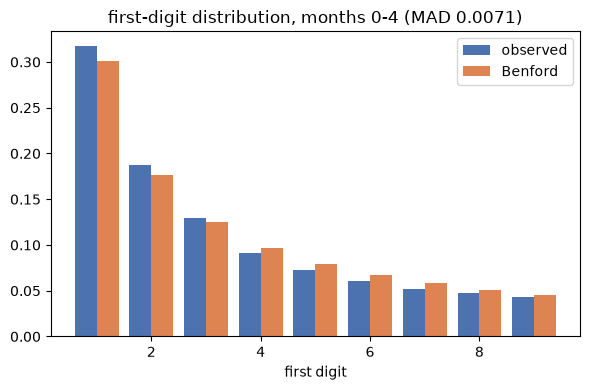

  [fig] outputs/modelling/eda/08_benford.png


In [8]:
header("7. BENFORD'S LAW ON ALL AMOUNTS (realism check for comment 1; not a feature)")

bf = con.execute(f"""
    SELECT CAST(substr(CAST(amount AS VARCHAR), 1, 1) AS INT) AS d, count(*) n
    FROM transactions x JOIN (SELECT account_id FROM accounts WHERE open_month IN ({months_sql})) a USING (account_id)
    WHERE amount >= 1 GROUP BY 1 HAVING d BETWEEN 1 AND 9 ORDER BY 1""").df().set_index("d")
bf["observed"] = bf["n"] / bf["n"].sum()
bf["benford"] = [np.log10(1 + 1 / d) for d in bf.index]
chi2 = float((((bf["observed"] - bf["benford"]) ** 2) / bf["benford"]).sum() * bf["n"].sum())
mad_ = float((bf["observed"] - bf["benford"]).abs().mean())
table(bf, floatfmt=".4f")
log(f"rows {int(bf['n'].sum()):,}; chi-square {chi2:,.0f} (any large sample rejects); Nigrini MAD {mad_:.4f} "
    f"(first digit: < 0.006 close, 0.006-0.012 acceptable, 0.012-0.015 marginal, > 0.015 nonconformity)")
log("  -> amounts are lognormal around published medians, so rough conformity is expected; it says the amount")
log("     mix is not absurd, nothing more. Each launderer has 3-15 laundering payments, far too few for Benford.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(bf.index - 0.2, bf["observed"], width=0.4, label="observed", color="#4c72b0")
ax.bar(bf.index + 0.2, bf["benford"], width=0.4, label="Benford", color="#dd8452")
ax.set_xlabel("first digit")
ax.set_title(f"first-digit distribution, months 0-4 (MAD {mad_:.4f})")
ax.legend()
savefig(fig, "08_benford")

## 8. Proposed feature list for Phase 3

A keep/drop proposal per candidate from the screen above: keep a feature when, at some screened week, its AUC for
`mule_by_day` or `started_by_day` is at least 0.05 from 0.5 (large enough to matter) and its 95% interval excludes 0.5
(not noise). The team fixed the Phase 3 list from this proposal on 15 Oct
2026 (`src/features/weekly.py`). The last cell writes the report.

In [9]:
header("8. PROPOSED FEATURE LIST FOR PHASE 3 (the team fixed it on 15 Oct 2026)")

separates = lambda name: (((screen[f"auc_{name}_lo"] > 0.5) | (screen[f"auc_{name}_hi"] < 0.5))
                          & ((screen[f"auc_{name}"] - 0.5).abs() >= MIN_SEP))
screen["separates"] = separates("mule_by_day") | separates("started_by_day")
best = screen.groupby("feature").agg(best_sep_mule=("auc_mule_by_day", lambda s: (s - 0.5).abs().max()),
                                     best_sep_started=("auc_started_by_day", lambda s: (s - 0.5).abs().max()),
                                     looks_separating=("separates", "sum"), nonnull=("nonnull_share", "min"))
best["proposal"] = np.where(best["looks_separating"] > 0, "keep", "drop (no screened week passes both tests)")
best.loc["night_share", "proposal"] += "; the simulator gives everyone the same hour weights (team dropped it 15 Oct)"
best = best.sort_values("best_sep_started", ascending=False)
table(best)
log(f"looks_separating: in how many of up to 8 looks (4 weeks x 2 labels) |AUC - 0.5| >= {MIN_SEP} and the 95% interval")
log("excludes 0.5. Both tests are needed: rare-event shares (mostly 0) get narrow intervals around tiny effects.")
log(f"Speed features separate started launderers: best |AUC - 0.5| vs started_by_day {best.loc['out_1h_share', 'best_sep_started']:.2f}"
    f" (out_1h_share) and {best.loc['out_24h_share', 'best_sep_started']:.2f} (out_24h_share).")
log(f"They are NaN in weeks with no money in (set in only {best.loc['out_1h_share', 'nonnull']:.0%} of screened account-weeks),"
    " and the AUC ranks NaN lowest. Correction 18 Oct 2026: the first version of")
log("this notebook ranked NaN highest by mistake, which made the speed shares look swamped by everyday outflows and led to")
log("a proposal to redefine them; the store keeps this definition (decision 15 Oct 2026).")
log("abroad_share, hr_share and cash_share are rare events at week level; the store keeps them cumulative (Phase 3).")
log("Application columns: keep all 29 after Phase 2 cleaning; LightGBM ignores useless ones and L1 logistic")
log("regression drops them. Candidate pairs above |0.8| correlation: keep one for the logistic model.")
log(f"\ndone in {time.time() - T0:.0f}s")

(REPORT / "report.md").write_text("\n".join(_lines), encoding="utf-8")
print(f"\nreport  -> {REPORT / 'report.md'}\nfigures -> {REPORT}")


8. PROPOSED FEATURE LIST FOR PHASE 3 (the team fixed it on 15 Oct 2026)
| feature             |   best_sep_mule |   best_sep_started |   looks_separating |   nonnull | proposal                                                                          |
|:--------------------|----------------:|-------------------:|-------------------:|----------:|:----------------------------------------------------------------------------------|
| n_rows_cum          |          0.2088 |             0.3642 |                  3 |    1.0000 | keep                                                                              |
| n_rows              |          0.1161 |             0.3045 |                  2 |    1.0000 | keep                                                                              |
| med_delay_min       |          0.1258 |             0.2890 |                  2 |    0.9999 | keep                                                                              |
| out_1h_share        |    